# Training-passage sentiment with VADER

The task labels describe musical content category, VADER helps us explore its tone by scoring positive and negative language. We use these scores to understand the training data, while keeping the original categories unchanged.

VADER is used to score the 140 training passages and plot them in a 40-bin histogram. Look at where the scores cluster to see whether the language leans positive or negative. Although, a score of zero does necessarily mean the tone is neautral. This step uses only training data and does not download any new resources, train a new model, or export out files.

## 1. Load the frozen training passages

In [1]:
from pathlib import Path
import csv
import hashlib
import json
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nltk.sentiment import SentimentIntensityAnalyzer
from IPython.display import display

project = Path.cwd()
if not (project / "music_review_pipeline.py").exists():
    project = project.parent
assert (project / "music_review_pipeline.py").is_file(), "Run from the repository root or notebooks folder."
path = project / "music_review_runs/2026-10-16_music_insight_AI_audit_v1/audited_splits/ai_audited_train.csv"
expected_hash = "3500dcd7e53b39a09fd5f78cd28eee94e9cb9ebc1d3e5e56d7fa69e784841096"
assert hashlib.sha256(path.read_bytes()).hexdigest() == expected_hash
with path.open(encoding="utf-8-sig", newline="") as handle:
    rows = list(csv.DictReader(handle))
assert len(rows) == 140
assert {row["split"] for row in rows} == {"train"}
assert len({row["passage_id"] for row in rows}) == 140
assert all(row["text"].strip() for row in rows)
df = pd.DataFrame(rows)
print("Training passages:", len(df))

Training passages: 140


## 2. Score the unchanged text

In [2]:
sia = SentimentIntensityAnalyzer()
scores = df["text"].apply(sia.polarity_scores)
df["sent_compound"] = scores.apply(lambda values: values["compound"])
assert df["sent_compound"].between(-1, 1).all()

counts = pd.Series({"Negative score": int((df["sent_compound"] < 0).sum()),
                    "Exactly zero": int((df["sent_compound"] == 0).sum()),
                    "Positive score": int((df["sent_compound"] > 0).sum())})
summary = pd.DataFrame({"passages": counts, "percent": 100 * counts / len(df)})
display(summary)
print("Mean compound:", statistics.mean(df["sent_compound"]))
print("Median compound:", statistics.median(df["sent_compound"]))

,passages,percent
Negative score,26,18.571429
Exactly zero,36,25.714286
Positive score,78,55.714286


Mean compound: 0.25824714285714284
Median compound: 0.23695


Case, punctuation, and negation were all retained during this analysis. Sign groups mean compound < 0,
== 0, and > 0. They do not use the conventional ±0.05 category thresholds.
Exactly zero can mean there is no recognized sentiment or balanced evidence, not necessarily a neutral opinion.

## 3. Plot the distribution

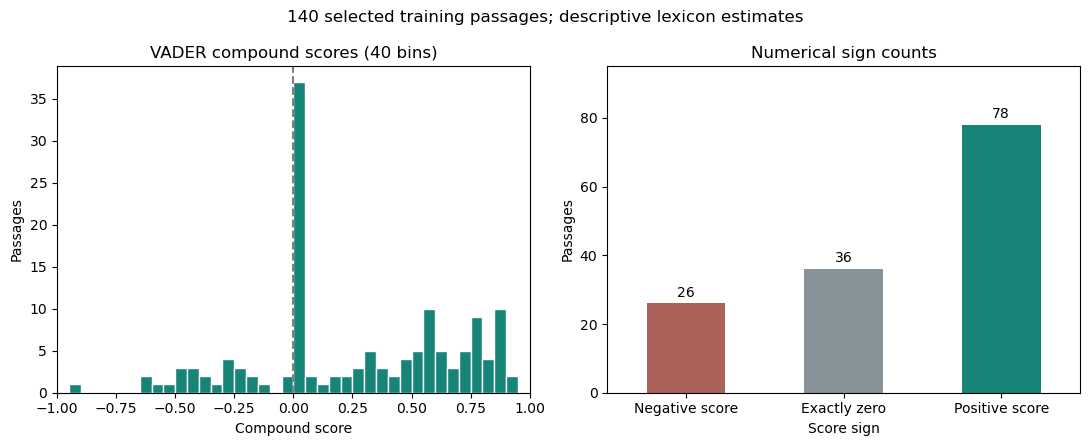

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
edges = np.linspace(-1, 1, 41)
axes[0].hist(df["sent_compound"], bins=edges, color="#168477", edgecolor="white")
axes[0].axvline(0, color="gray", linestyle="--")
axes[0].set(title="VADER compound scores (40 bins)", xlabel="Compound score", ylabel="Passages", xlim=(-1, 1))
counts.plot.bar(ax=axes[1], color=["#ad6259", "#889399", "#168477"], rot=0)
axes[1].set(title="Numerical sign counts", xlabel="Score sign", ylabel="Passages", ylim=(0, 95))
for i, value in enumerate(counts):
    axes[1].text(i, value + 2, str(value), ha="center")
fig.suptitle("140 selected training passages; descriptive lexicon estimates")
plt.tight_layout()
plt.show()

## 4. Check against the saved analysis

In [4]:
saved_path = project / "09_training_sentiment_EDA_VADER/results/sentiment_summary.json"
saved = json.loads(saved_path.read_text())
assert counts.tolist() == [saved["sign_counts"][key] for key in ["negative_score", "zero_score", "positive_score"]]
assert statistics.mean(df["sent_compound"]) == saved["compound"]["mean"]
assert statistics.median(df["sent_compound"]) == saved["compound"]["median"]
hist, _ = np.histogram(df["sent_compound"], bins=edges)
assert hist.tolist() == saved["histogram"]["counts"]

saved_scores = pd.read_csv(project / "09_training_sentiment_EDA_VADER/results/training_vader_scores.csv")
assert df["passage_id"].tolist() == saved_scores["passage_id"].tolist()
assert np.array_equal(df["sent_compound"].to_numpy(), saved_scores["vader_compound"].to_numpy())
assert hashlib.sha256(path.read_bytes()).hexdigest() == expected_hash
print("PASS: all 140 compound scores, counts, mean, median, and histogram match.")

PASS: all 140 compound scores, counts, mean, median, and histogram match.


These are 140 selected training passages, not the full 500-review corpus or
all listeners. Short excerpts, missing context, sarcasm, and music vocabulary can
affect VADER. No human sentiment validation was performed. The existing script
and PNG/SVG remain in `../09_training_sentiment_EDA_VADER/`.